# Regularization and generalization

## 1. Introduction and learning objectives

Training error measures agreement with observed training rows. Generalization concerns new observations from a declared population. This chapter connects that distinction to squared-loss bias–variance, learning curves, feature scaling, and manual L2 objectives for regression and classification. L1 is a conceptual comparison here; its optimizer is outside this delivery.

After the three earlier Stage 01 chapters, you should be able to derive an objective and its gradient, explain how a penalty changes the estimate, and select its strength using data that did not fit that estimate. All observations are rows; targets and weight vectors have shapes (n,) and (d,).

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 01.04.01 — Distinguish two risks

**Type:** Conceptual · **Answer:** Markdown

Define empirical risk and population risk for a fitted predictor. Can a training loss of zero establish that population risk is zero? State the sampling assumption behind using a held-out mean loss.

**Expected outcome:** two mathematical definitions and an explicit inference limitation.

**Your response to Exercise 01.04.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.04.01**

Population risk averages over a new random observation, not over the same fitted rows.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.04.01**

Empirical risk is n⁻¹Σ_i ℓ(f̂(x_i),y_i). Population risk conditional on the fitted model is E_(X,Y)[ℓ(f̂(X),Y)] for a specified distribution. Zero empirical risk does not rule out overfitting, noise, or distribution shift. A held-out sample mean estimates that conditional risk when observations follow the target sampling distribution and were not used for fitting or selection; repeated tuning on it weakens that interpretation.

</details>

## 2. Prerequisites and mathematical foundations

Let a training sample D produce f̂_D. Suppose Y=f*(x)+ε, where E[ε | x]=0, Var(ε | x)=σ²(x), and a fresh test noise is independent of D conditional on x. Add and subtract E_D f̂_D(x) inside the squared error. Cross-terms vanish after expectation, yielding

$$E_{D,Y\mid x}[(Y-\hat f_D(x))^2]=
\sigma^2(x)+\big(E_D\hat f_D(x)-f^*(x)\big)^2+
E_D\big[(\hat f_D(x)-E_D\hat f_D(x))^2\big].$$

These are irreducible noise, squared bias, and prediction variance. Integrate over x for integrated risk. This is a decomposition across repeated training datasets, not the variance of predictions over unrelated x values. It does not apply unchanged to cross-entropy or classification error. More flexible models can reduce approximation bias while increasing estimation variance, but that is a tendency under assumptions, not a universal monotonic law.

### Exercise 01.04.02 — Derive the vanished cross-term

**Type:** Mathematical · **Answer:** Markdown

At fixed x, write f̂_D=m+δ_D with E_D δ_D=0. Expand (f*+ε−m−δ_D)² and identify the assumptions that remove each cross-term.

**Expected outcome:** the three-term squared-loss decomposition with a statement about fresh test noise.

**Your response to Exercise 01.04.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.04.02**

Condition on x before taking expectations; independence of the new noise and the fitted model matters.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.04.02**

The expansion contains (f*−m)²+ε²+δ_D²+2(f*−m)ε−2(f*−m)δ_D−2εδ_D. The first two mixed terms vanish by zero conditional means. The final one vanishes because fresh test noise is independent of the training sample and has zero conditional mean. Reusing training noise can invalidate that last step and make training error optimistic.

</details>

## 3. Theoretical development and worked examples

### Specify the penalty's normalization

For affine predictions Xw+b, use

$$J_{\rm ridge}=\frac1{2n}\|Xw+b-y\|_2^2+\frac\lambda2\|w\|_2^2,
\quad \nabla_wJ=X^Tr/n+\lambda w,\quad \partial_bJ=\operatorname{mean}(r).$$

The intercept is unpenalized. λ≥0 has the same definition for every n: do not divide the penalty by n again. The reported predictive MSE is mean(r²), while this objective uses **half** MSE plus a penalty. Report data loss and objective separately.

Eliminate b by centering training columns and targets. With X_c and y_c centered,

$$ (X_c^TX_c+n\lambda I)w=X_c^Ty_c,\qquad b=\bar y-\bar x^Tw.$$

For λ>0 the left matrix is positive definite. For λ=0, a rank-deficient design needs an explicit least-squares policy. Solving is preferable to forming an inverse. A simple worked case is X=(−1,1)ᵀ and y=(−3,3)ᵀ: b=0, J=(w−3)²/2+λw²/2, so w=3/(1+λ). At λ=1, w=1.5 and both half data loss and penalty are 1.125.

For binary labels, z=Xw+b and

$$J_{\rm logistic}=\frac1n\sum_i[\log(1+e^{z_i})-y_i z_i]+\frac\lambda2\|w\|^2,
\quad \nabla_wJ=X^T(p-y)/n+\lambda w,\quad \partial_bJ=\operatorname{mean}(p-y).$$

Use stable softplus and sigmoid as reviewed in Stage 00. Penalizing weights can stop their divergence on separable data, but an unpenalized intercept can still diverge with a single observed class. The training routine below therefore requires both classes.

### L1 and feature units

L2 contours are smooth spheres; L1 uses λΣ_j|w_j| and has corners on coordinate axes. At nonzero coordinates its derivative is λ sign(w_j); at zero its subgradient spans [−λ,λ]. L1 can produce exact zeros; L2 generally shrinks coefficients continuously. Neither means a correlated feature's coefficient is causal. Scaling x by 100 rescales the coefficient needed for the same predictions and changes its penalty. Fit standardization on the training partition, or separately inside each CV fold, before comparing penalty strengths.

### Exercise 01.04.03 — Calculate a regularized snapshot

**Type:** Numerical · **Answer:** Markdown

Use X=[(1,0),(0,2)], y=(2,1), w=(0,1), b=0, λ=.2. Compute ridge data loss, penalty, objective, and both gradients.

**Expected outcome:** distinguish half-MSE from the full objective and keep the intercept unpenalized.

**Your response to Exercise 01.04.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.04.03**

The residual vector is (−2,1), and the penalty gradient is (0,.2).

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.04.03**

Half-MSE=(4+1)/4=1.25, penalty=.2/2=.1, objective=1.35. Data weight gradient is (−1,1), so the regularized gradient is (−1,1.2). Bias gradient is (−2+1)/2=−.5. Duplicating every observation leaves these mean-objective gradients unchanged at fixed λ; adding a second division by n would violate that invariance.

</details>

## 4. Guided exercises

Learning curves compare training and validation error as training sample size increases, with validation data held fixed. A gap can suggest variance, while high errors on both can suggest underfitting, noise, a bad objective, or failed optimization. Inspect convergence and baselines before diagnosing capacity. A regularization path compares models across λ; feature units and data splits must be fixed for a meaningful comparison.

### Exercise 01.04.04 — Compare L1 and L2 without implementing L1

**Type:** Conceptual · **Answer:** Markdown

Why can L1 set a coefficient exactly to zero while L2 often does not? What happens when two features are near duplicates? State why neither penalty makes feature selection a causal claim.

**Expected outcome:** a geometric or subgradient explanation with limitations.

**Your response to Exercise 01.04.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.04.04**

At zero, L1 offers an interval of balancing subgradients. Correlated features can substitute for one another.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.04.04**

The L1 corner permits a data gradient within [−λ,λ] to be balanced at zero. L2's penalty gradient is zero at zero and grows smoothly away from it, so exact sparsity is not its usual effect. Correlated predictors can yield unstable individual coefficients or alternate sparse choices, even with stable predictions; L2 often distributes weight. Predictive selection concerns association under the observed distribution, not interventions or confounding.

</details>

## 5. Implementation challenges

### Exercise 01.04.05 — Implement ridge loss and its closed-form fit

**Type:** Programming · **Answer:** Code

Implement `ridge_loss_gradient(X,y,w,b,penalty)` and `fit_ridge(X,y,penalty)`. Reject malformed/nonfinite inputs and negative penalty. Use least squares on centered data at λ=0; otherwise solve the derived system. Verify the hand example, finite differences, and stationarity at the fitted parameters.

**Expected outcome:** correctly scaled gradients, no input mutation, and a rank-deficient λ=0 case with a stated policy.

In [ ]:
# Your code for Exercise 01.04.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.04.05**

Share a local validator, but write the independent numerical objective separately.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.04.05**

This validator is reused by the later logistic reference. The λ=0 policy is NumPy's minimum-norm centered least-squares solution. The positive-penalty solve is mathematically well defined, though extremely small penalties may still need conditioning diagnostics.

~~~python
def supervised_parameters(X, y, w, b, penalty):
    X, y, w = (np.asarray(a, dtype=float) for a in (X, y, w))
    if X.ndim != 2 or min(X.shape) == 0 or y.shape != (len(X),) or w.shape != (X.shape[1],):
        raise ValueError("expected X(n,d), y(n,), w(d,)")
    if np.ndim(b) != 0 or np.ndim(penalty) != 0:
        raise ValueError("scalar bias and penalty required")
    if not all(np.isfinite(a).all() for a in (X, y, w, np.asarray(b), np.asarray(penalty))) or penalty < 0:
        raise ValueError("finite inputs and nonnegative penalty required")
    return X, y, w, float(b), float(penalty)

def ridge_loss_gradient(X, y, w, b, penalty=0.):
    X, y, w, b, penalty = supervised_parameters(X, y, w, b, penalty)
    residual = X @ w + b - y
    loss = np.mean(residual**2) / 2 + penalty * (w @ w) / 2
    return float(loss), X.T @ residual / len(X) + penalty * w, float(residual.mean())

def fit_ridge(X, y, penalty=0.):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2:
        raise ValueError("matrix required")
    X, y, _, _, penalty = supervised_parameters(X, y, np.zeros(X.shape[1]), 0., penalty)
    center, target_center = X.mean(axis=0), y.mean()
    A, target = X - center, y - target_center
    if penalty == 0:
        w = np.linalg.lstsq(A, target, rcond=None)[0]
    else:
        w = np.linalg.solve(A.T @ A + len(X) * penalty * np.eye(X.shape[1]), A.T @ target)
    return w, float(target_center - center @ w)
~~~

</details>

### Exercise 01.04.06 — Implement regularized logistic regression

**Type:** Programming · **Answer:** Code

Implement `regularized_logistic_loss_gradient` and a full-batch `fit_regularized_logistic` with fixed step size and update count. Reject nonbinary targets; fitting requires both classes. Return parameters and objective history including the initial and final states. Never update one parameter before computing the other's gradient.

**Expected outcome:** independent gradient checks at n=1 and n>1, stable extreme logits, and training diagnostics.

In [ ]:
# Your code for Exercise 01.04.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.04.06**

Reuse only the validation helper from the preceding reference. Mask the sigmoid by sign and add λw exactly once.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.04.06**

This depends on `supervised_parameters`. The fixed-work optimizer is intentionally small; its returned history lets you detect a poor step size. Finite loss alone is not convergence. At a stable step, inspect gradient norm and sensitivity to doubling the update budget before trusting comparisons.

~~~python
def regularized_logistic_loss_gradient(X, y, w, b, penalty=0.):
    X, y, w, b, penalty = supervised_parameters(X, y, w, b, penalty)
    if not np.isin(y, [0, 1]).all():
        raise ValueError("binary labels required")
    z = X @ w + b
    p = np.empty_like(z)
    positive = z >= 0
    p[positive] = 1 / (1 + np.exp(-z[positive]))
    e = np.exp(z[~positive]); p[~positive] = e / (1 + e)
    loss = np.mean(np.logaddexp(0, z) - y * z) + penalty * (w @ w) / 2
    return float(loss), X.T @ (p - y) / len(X) + penalty * w, float(np.mean(p - y))

def fit_regularized_logistic(X, y, penalty=.1, rate=.1, steps=800):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2:
        raise ValueError("matrix required")
    X, y, w, b, penalty = supervised_parameters(X, y, np.zeros(X.shape[1]), 0., penalty)
    if not np.isin(y, [0, 1]).all() or len(np.unique(y)) != 2:
        raise ValueError("fitting requires both binary classes")
    if not np.isfinite(rate) or rate <= 0 or not isinstance(steps, (int, np.integer)) or steps < 1:
        raise ValueError("positive rate and integer steps required")
    history = []
    for _ in range(steps):
        loss, dw, db = regularized_logistic_loss_gradient(X, y, w, b, penalty)
        if not np.isfinite(loss):
            raise FloatingPointError("nonfinite training objective")
        history.append(loss)
        w, b = w - rate * dw, b - rate * db
    history.append(regularized_logistic_loss_gradient(X, y, w, b, penalty)[0])
    return w, b, np.asarray(history)
~~~

</details>

## 6. Experiments and visualizations

This one-coordinate worked example visualizes the already-derived tradeoff. It does not implement a general fitting function. Validation is not shown because the two-row example is an algebraic illustration, not evidence of predictive improvement.

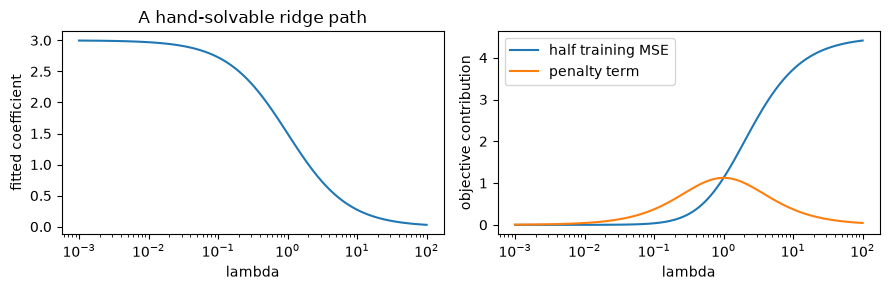

In [2]:
penalties = np.logspace(-3, 2, 120)
weights = 3 / (1 + penalties)
data_loss = (weights - 3)**2 / 2
penalty_term = penalties * weights**2 / 2
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].semilogx(penalties, weights)
axes[0].set(xlabel="lambda", ylabel="fitted coefficient", title="A hand-solvable ridge path")
axes[1].semilogx(penalties, data_loss, label="half training MSE")
axes[1].semilogx(penalties, penalty_term, label="penalty term")
axes[1].set(xlabel="lambda", ylabel="objective contribution"); axes[1].legend()
fig.tight_layout(); plt.show()

### Exercise 01.04.07 — Measure learning curves without test tuning

**Type:** Experimental · **Answer:** Code

Generate 400 rows with eight standard-normal features and y=2x₀−x₁+noise, noise standard deviation 1, seed 45. Use the first 250 as a training pool and the remaining 150 as validation. Compare λ∈{0,.1,1} and training sizes 20,50,100,250. Plot train/validation MSE and discuss optimization versus estimation.

**Expected outcome:** actual curves, fixed validation rows, and no test-based choice.

In [ ]:
# Your code for Exercise 01.04.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.04.07**

The features are already generated in common units. On real data, fit scaling within each training subset.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.04.07**

This depends on `fit_ridge`. Closed-form fitting removes iterative-optimization error as a major confounder for this small example. Prefix subsets are nested, so their errors are correlated; one realization is not a population guarantee.

~~~python
rng = np.random.default_rng(45)
X = rng.normal(size=(400, 8)); y = 2 * X[:, 0] - X[:, 1] + rng.normal(size=400)
sizes = [20, 50, 100, 250]
for penalty in (0., .1, 1.):
    training, validation = [], []
    for n in sizes:
        w, b = fit_ridge(X[:n], y[:n], penalty)
        training.append(np.mean((X[:n] @ w + b - y[:n])**2))
        validation.append(np.mean((X[250:] @ w + b - y[250:])**2))
    print(penalty, training, validation)
    plt.plot(sizes, validation, "o-", label=f"validation lambda={penalty}")
    plt.plot(sizes, training, "--", alpha=.6)
plt.xlabel("training rows"); plt.ylabel("MSE"); plt.legend(); plt.show()
~~~

</details>

### Exercise 01.04.08 — Estimate squared bias and variance at fixed x

**Type:** Experimental · **Answer:** Code

Fit a one-feature linear ridge model to 100 independently generated datasets of size 15 from y=2x+noise with x uniform on [−1,1] and unit-variance Gaussian noise. At x=.7, compare λ=0 and 1. Estimate prediction squared bias and variance using denominator 100. Compare their sum with mean squared error relative to the noiseless target.

**Expected outcome:** the finite-replicate identity, then an explanation of the additional test-noise term for predicting Y.

In [ ]:
# Your code for Exercise 01.04.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.04.08**

Use identical datasets for both penalties. Vary training datasets, not the evaluation x.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.04.08**

This depends on `fit_ridge`. For the finite vector of predictions, average squared deviation from the target equals squared empirical bias plus empirical variance exactly with denominator 100. Adding population noise variance 1 gives an estimated expected squared error for a fresh noisy response, under the stated model.

~~~python
rng = np.random.default_rng(46)
predictions = {0.: [], 1.: []}
for repeat in range(100):
    X = rng.uniform(-1, 1, size=(15, 1)); y = 2 * X[:, 0] + rng.normal(size=15)
    for penalty in predictions:
        w, b = fit_ridge(X, y, penalty)
        predictions[penalty].append(.7 * w[0] + b)
for penalty, values in predictions.items():
    values = np.asarray(values)
    squared_bias, variance = (values.mean() - 1.4)**2, np.var(values, ddof=0)
    print(penalty, squared_bias, variance, np.mean((values - 1.4)**2))
    np.testing.assert_allclose(squared_bias + variance, np.mean((values - 1.4)**2))
~~~

</details>

## 7. Interpretation and critical analysis

### Exercise 01.04.09 — Diagnose a misleading penalty comparison

**Type:** Critical · **Answer:** Markdown

Model A trains for 10 steps with λ=0; model B trains for 1000 steps with λ=.1 and has lower validation loss. An author concludes L2 caused the improvement. Identify confounders and propose a controlled comparison.

**Expected outcome:** a matched split/preprocessing/work protocol and convergence evidence.

**Your response to Exercise 01.04.09**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.04.09**

Penalty strength is not the only changed variable. Early stopping can itself change the fitted estimate.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.04.09**

The optimization budget is confounded with the penalty. Use the same splits, scaling, initialization policy, optimizer schedule, selection metric, and declared work budget; also inspect convergence or compare sufficiently converged solutions. Report training data loss, regularized objective, gradient norm, runtime, and validation metric separately. Matched work and matched convergence answer different questions; label which is used. Repeat data seeds if claiming a systematic benefit.

</details>

## 8. Review questions and knowledge checks

### Exercise 01.04.10 — Check invariance to repeated rows

**Type:** Mathematical · **Answer:** Markdown

If every training row is duplicated, should the mean L2 objective and gradient at fixed w,b,λ change? Should the derived ridge system produce a different solution?

**Expected outcome:** show the cancellation in both the objective and centered normal equations.

**Your response to Exercise 01.04.10**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 01.04.10**

The Gram matrix, right-hand side, and n all double.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 01.04.10**

The mean data loss and gradient are unchanged; the penalty is unchanged by definition. In the ridge system, X_cᵀX_c, X_cᵀy_c, and nλI all double, so the same w solves it and the means give the same b. A penalty divided by n would break this invariant. This algebraic check does not mean duplicated rows are additional independent statistical evidence.

</details>

## 9. Summary and next learning steps

Explain empirical versus population risk and the squared-loss assumptions; implement both L2 gradients and a ridge solve; verify scaling and derivatives independently; evaluate learning curves without overclaiming from one seed. Continue to [evaluation and model selection](evaluation-and-model-selection.ipynb), then the [Stage 01 project](../../projects/01-ml-pipeline/ml-pipeline.ipynb).